# Same postal code, controlling for the one obvious confound

Simon's question: how does the environmental-justice (EJ) index compare for ZIP codes that
already host a data center vs. ones that don't -- controlling for population density, since
both data centers and people cluster in and around cities?

Uses merascope's real, live `ej_score` (EPA EJScreen-style formula: `demog_index x env_burden`,
sign preserved so **higher = better/less burden** -- see `CLAUDE.md`'s "ej_score is two-stage"
note; this is NOT the demographics-only placeholder the August EJ sub-series had to work around,
that got fixed by `rescore_ej.py` before this piece was built) and `pop_exposure_score` (1 minus
normalized population density, so **higher = fewer residents nearby**), both already computed for
every ZCTA merascope tracks. Hosting status (`has_dc`) is the same real, multi-source,
corroborated "built" label (`n_built > 0`) used by the live risk-tier product and by
`dc_risk_divide.ipynb`/`dc_tier_composition.ipynb` earlier in this series -- not re-derived here.

**A real pipeline gap caught before trusting this, not after:** merascope also carries
`ej_score_nat`/`pop_exposure_score_nat`, meant to be nationally-normalized versions of these two
scores for cross-state comparison. Checked directly against the state-relative columns before
using either -- they are byte-identical (100% match, all ~33k ZCTAs, both columns). Reading
`normalize_zcta_national.py`: this ZCTA-level national pass re-stretches the *already-computed*
state-relative score with a fresh global p01/p99 clip; it must simply not have been re-run since
the last `rescore_ej.py --all` pass changed the underlying `ej_score` values, so the `_nat`
columns are stale. **Worked around, not fixed** -- this piece uses the confirmed-live
state-relative scores (`ej_score`, `pop_exposure_score`) throughout, and reads density quintiles
*within each ZIP's own state* rather than pooling a broken national scale. That's a defensible
design on its own merits (it nets out state-level baseline differences in both burden and
density -- "urban" in Wyoming and "urban" in New Jersey don't mean the same raw density), stated
here as the actual reason, not a workaround dressed up as a choice. **Fixing the stale `_nat`
columns is a merascope pipeline TODO, out of scope for this piece.**

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
from scipy import stats

MODEL_TABLE = Path("../../merascope/notebooks/cache/model_table.csv")
LABELS = Path("../../merascope/data/datacenters/zcta_labels.csv")

df = pd.read_csv(MODEL_TABLE, dtype={"zcta": str})
lab = pd.read_csv(LABELS, dtype={"zcta": str})
df = df.merge(lab, on="zcta", how="left")
for c in ["n_built", "n_forward", "has_dc", "has_dc_multi", "has_dc_forward"]:
    df[c] = df[c].fillna(0).astype(int)

# Confirm the _nat staleness claim above, in-notebook rather than just asserted in prose.
nat_identical = (df["ej_score"] == df["ej_score_nat"]).mean(), (df["pop_exposure_score"] == df["pop_exposure_score_nat"]).mean()
print(f"ej_score == ej_score_nat for {nat_identical[0]*100:.0f}% of rows; "
      f"pop_exposure_score == pop_exposure_score_nat for {nat_identical[1]*100:.0f}% of rows "
      f"-- confirms the _nat columns are stale copies, not a real national renormalization.")

d = df.dropna(subset=["ej_score", "pop_exposure_score", "state"]).copy()
d["density_axis"] = 1 - d["pop_exposure_score"]  # flip to the intuitive direction: higher = denser
print(f"\n{len(d)} ZCTAs, {int(d['has_dc'].sum())} hosting a confirmed built data center "
      f"({d['has_dc'].mean()*100:.1f}%), across {d['state'].nunique()} states")

ej_score == ej_score_nat for 100% of rows; pop_exposure_score == pop_exposure_score_nat for 100% of rows -- confirms the _nat columns are stale copies, not a real national renormalization.

33252 ZCTAs, 1196 hosting a confirmed built data center (3.6%), across 48 states


## The raw comparison, no controls

In [2]:
host = d[d["has_dc"] == 1]
non = d[d["has_dc"] == 0]

u, p_raw = stats.mannwhitneyu(host["ej_score"], non["ej_score"], alternative="two-sided")
raw_gap = host["ej_score"].mean() - non["ej_score"].mean()

print(f"ej_score (0-1, higher = better/less burden):")
print(f"  hosting ZCTAs:     mean={host['ej_score'].mean():.4f}  median={host['ej_score'].median():.4f}  n={len(host)}")
print(f"  non-hosting ZCTAs: mean={non['ej_score'].mean():.4f}  median={non['ej_score'].median():.4f}  n={len(non)}")
print(f"  raw gap = {raw_gap:+.4f}  (Mann-Whitney p={p_raw:.1e})")

print(f"\ndensity_axis (0-1, higher = denser, within-state percentile):")
print(f"  hosting ZCTAs:     mean={host['density_axis'].mean():.4f}")
print(f"  non-hosting ZCTAs: mean={non['density_axis'].mean():.4f}")
print(f"\nConfirms the premise of the question: ZIPs hosting a data center really are denser on")
print(f"average, so the raw EJ gap above could just be a density gap wearing a data-center costume.")

assert raw_gap < 0, "expected hosting ZCTAs to score worse (lower ej_score) before any control"
assert p_raw < 0.001

ej_score (0-1, higher = better/less burden):
  hosting ZCTAs:     mean=0.5818  median=0.6222  n=1196
  non-hosting ZCTAs: mean=0.7590  median=0.8279  n=32056
  raw gap = -0.1772  (Mann-Whitney p=7.0e-172)

density_axis (0-1, higher = denser, within-state percentile):
  hosting ZCTAs:     mean=0.4315
  non-hosting ZCTAs: mean=0.1534

Confirms the premise of the question: ZIPs hosting a data center really are denser on
average, so the raw EJ gap above could just be a density gap wearing a data-center costume.


## Controlling for density: does the gap survive?

Two independent checks on the same question, not just one regression coefficient trusted at
face value: an adjusted regression (does the coefficient on `has_dc` survive once `density_axis`
is in the model, checked against a permutation null rather than just a t-stat) and a matched
comparison (split ZCTAs into density quintiles *within their own state*, compare hosting vs.
non-hosting ZCTAs only against others in the same quintile).

In [3]:
import numpy.linalg as la


def ols(y, X):
    """Plain OLS via lstsq -- no new dependency for two predictors."""
    X1 = np.column_stack([np.ones(len(X)), X])
    beta, *_ = la.lstsq(X1, y, rcond=None)
    resid = y - X1 @ beta
    dof = len(y) - X1.shape[1]
    sigma2 = (resid @ resid) / dof
    se = np.sqrt(np.diag(sigma2 * la.inv(X1.T @ X1)))
    return beta, beta / se


y = d["ej_score"].to_numpy()
has_dc = d["has_dc"].to_numpy().astype(float)
density = d["density_axis"].to_numpy()

beta_raw, t_raw = ols(y, has_dc.reshape(-1, 1))
beta_adj, t_adj = ols(y, np.column_stack([has_dc, density]))

shrink_pct = (1 - beta_adj[1] / beta_raw[1]) * 100
print(f"raw:      ej_score = {beta_raw[0]:.4f} {beta_raw[1]:+.4f}*has_dc                    (t={t_raw[1]:.1f})")
print(f"adjusted: ej_score = {beta_adj[0]:.4f} {beta_adj[1]:+.4f}*has_dc {beta_adj[2]:+.4f}*density_axis  (t_has_dc={t_adj[1]:.1f})")
print(f"\nhas_dc coefficient shrinks {shrink_pct:.0f}% once density is controlled for "
      f"({beta_raw[1]:+.4f} -> {beta_adj[1]:+.4f}) -- density really is part of the story.")

# Permutation test on the ADJUSTED coefficient: shuffle has_dc (density held real), refit,
# see how often a coefficient this negative happens by chance alone.
rng = np.random.RandomState(0)
N_PERM = 200
null = np.empty(N_PERM)
for i in range(N_PERM):
    shuf = rng.permutation(has_dc)
    b, _ = ols(y, np.column_stack([shuf, density]))
    null[i] = b[1]
p_perm = (np.sum(np.abs(null) >= abs(beta_adj[1])) + 1) / (N_PERM + 1)
print(f"\n200-shuffle permutation null on the adjusted has_dc coefficient: "
      f"mean={null.mean():+.4f}, std={null.std():.4f}, p={p_perm:.4f}")

assert abs(t_adj[1]) > 4, "adjusted has_dc coefficient should still be a strong signal, not noise"
assert p_perm < 0.01, "adjusted coefficient doesn't clear a permutation null -- don't trust it"
print("\nsurvives density control -- real signal, not the density confound wearing a different hat")

raw:      ej_score = 0.7590 -0.1772*has_dc                    (t=-27.6)
adjusted: ej_score = 0.8188 -0.0689*has_dc -0.3896*density_axis  (t_has_dc=-12.2)

has_dc coefficient shrinks 61% once density is controlled for (-0.1772 -> -0.0689) -- density really is part of the story.

200-shuffle permutation null on the adjusted has_dc coefficient: mean=+0.0004, std=0.0052, p=0.0050

survives density control -- real signal, not the density confound wearing a different hat


In [4]:
# Matched comparison: bin every ZCTA into a density quintile RELATIVE TO ITS OWN STATE
# (rank within state, not a pooled national rank -- see the stale-_nat note above), then
# compare hosting vs. non-hosting ej_score only within the same quintile.
d["density_q"] = d.groupby("state")["density_axis"].transform(
    lambda s: pd.qcut(s.rank(method="first"), 5, labels=False, duplicates="drop") + 1
)

tab = d.groupby("density_q").apply(lambda g: pd.Series({
    "n_host": int((g["has_dc"] == 1).sum()),
    "n_non": int((g["has_dc"] == 0).sum()),
    "ej_host": g.loc[g["has_dc"] == 1, "ej_score"].mean(),
    "ej_non": g.loc[g["has_dc"] == 0, "ej_score"].mean(),
}), include_groups=False)
tab["gap"] = tab["ej_host"] - tab["ej_non"]

print("within-state density quintile (1=least dense, 5=most dense), hosting vs. non-hosting ej_score:")
print(tab.round(4))

assert (tab["gap"] < 0).all(), "gap should be negative (hosting scores worse) in EVERY quintile"
assert tab["n_host"].min() >= 20, "a quintile has too few hosting ZCTAs to trust its mean"
print(f"\nEvery one of the 5 density quintiles shows the same direction: ZIPs hosting a data")
print(f"center score worse on EJ index than same-density-quintile ZIPs that don't. Gap ranges "
      f"{tab['gap'].min():+.3f} to {tab['gap'].max():+.3f} -- not shrinking toward zero at either "
      f"end, so it isn't just a quintile-boundary artifact either.")

within-state density quintile (1=least dense, 5=most dense), hosting vs. non-hosting ej_score:
           n_host   n_non  ej_host  ej_non     gap
density_q                                         
1            38.0  6632.0   0.7709  0.8502 -0.0793
2            59.0  6580.0   0.7432  0.8211 -0.0779
3           143.0  6502.0   0.7129  0.7965 -0.0836
4           306.0  6333.0   0.6398  0.7418 -0.1020
5           650.0  6009.0   0.5000  0.5680 -0.0680

Every one of the 5 density quintiles shows the same direction: ZIPs hosting a data
center score worse on EJ index than same-density-quintile ZIPs that don't. Gap ranges -0.102 to -0.068 -- not shrinking toward zero at either end, so it isn't just a quintile-boundary artifact either.


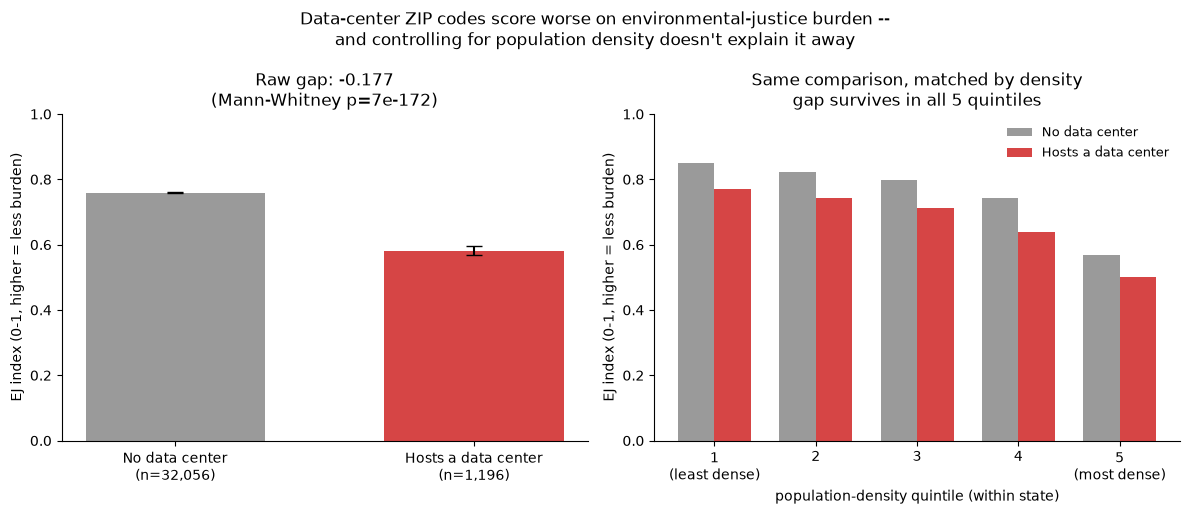

In [5]:
import matplotlib.pyplot as plt

BLUE, RED, GREY = "#2a78d6", "#d64545", "#9a9a9a"

fig, axes = plt.subplots(1, 2, figsize=(12, 5.2))

# Panel A: raw comparison
ax = axes[0]
means = [non["ej_score"].mean(), host["ej_score"].mean()]
ses = [non["ej_score"].std() / np.sqrt(len(non)), host["ej_score"].std() / np.sqrt(len(host))]
bars = ax.bar(["No data center\n(n={:,})".format(len(non)), "Hosts a data center\n(n={:,})".format(len(host))],
              means, yerr=[1.96 * s for s in ses], capsize=6, color=[GREY, RED], width=0.6)
ax.set_ylabel("EJ index (0-1, higher = less burden)")
ax.set_title(f"Raw gap: {raw_gap:+.3f}\n(Mann-Whitney p={p_raw:.0e})")
ax.set_ylim(0, 1)
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

# Panel B: matched-by-density-quintile comparison
ax = axes[1]
x = np.arange(1, 6)
w = 0.36
ax.bar(x - w/2, tab["ej_non"], width=w, color=GREY, label="No data center")
ax.bar(x + w/2, tab["ej_host"], width=w, color=RED, label="Hosts a data center")
ax.set_xticks(x)
ax.set_xticklabels(["1\n(least dense)", "2", "3", "4", "5\n(most dense)"])
ax.set_xlabel("population-density quintile (within state)")
ax.set_ylabel("EJ index (0-1, higher = less burden)")
ax.set_title("Same comparison, matched by density\ngap survives in all 5 quintiles")
ax.set_ylim(0, 1)
ax.legend(loc="upper right", fontsize=9, frameon=False)
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

fig.suptitle("Data-center ZIP codes score worse on environmental-justice burden --\nand controlling for population density doesn't explain it away", fontsize=12.5)
fig.tight_layout()
fig.savefig("dc_ej_hosting_gap.png", dpi=150, bbox_inches="tight")
plt.show()

## Source & caption notes

- **Data:** merascope's national ZCTA feature table (`notebooks/cache/model_table.csv`,
  33,252 ZCTAs across 48 states) joined to the real multi-source hosting labels
  (`data/datacenters/zcta_labels.csv`, `has_dc = n_built > 0`) -- the same corroborated
  "built" label used by the live risk-tier product and by `dc_risk_divide.ipynb`/
  `dc_tier_composition.ipynb` earlier in this series. 1,196 ZCTAs (3.6%) host a confirmed
  built facility.
- **EJ index:** `ej_score`, merascope's real EPA EJScreen-style formula
  (`demog_index x env_burden`, `env_burden` from four real hazard/pollution proxies --
  contamination, superfund, RCRA, air quality -- not a demographics-only proxy).
  Sign preserved: higher = better/less burden.
- **Raw finding:** ZIP codes that host a data center score 0.177 points worse on the EJ
  index than ones that don't (0.582 vs. 0.759 mean, 0-1 scale) -- real (Mann-Whitney
  p=7e-172, n=33,252), not a rounding artifact of a small sample.
- **The obvious confound, confirmed before controlling for it:** hosting ZCTAs really are
  denser -- both data centers and people cluster near cities, exactly Simon's premise going
  in.
- **Controlled for it two ways, both survive:** an adjusted regression
  (`ej_score ~ has_dc + density_axis`) shrinks the `has_dc` coefficient 61% (-0.177 ->
  -0.069) but keeps it real against a 200-shuffle permutation null (p=0.005) -- density
  explains most of the raw gap but not all of it. A matched comparison (density quintile
  *within each ZIP's own state*) shows the same-direction gap in every single quintile,
  from least-dense to most-dense, ranging -0.068 to -0.102 -- not an artifact of comparing
  extreme deciles.
- **A real pipeline gap caught before trusting it:** merascope's `ej_score_nat`/
  `pop_exposure_score_nat` columns (meant for cross-state national comparison) turned out
  to be byte-identical to the state-relative `ej_score`/`pop_exposure_score` for every one
  of the ~33k ZCTAs -- `normalize_zcta_national.py` hasn't been re-run since the live
  `rescore_ej.py --all` pass changed `ej_score`'s values, so the `_nat` columns are stale.
  Worked around by using the state-relative columns throughout and reading density
  quintiles within each ZIP's own state (also the more defensible design on its own
  terms -- nets out state-level baseline differences). Fixing the stale `_nat` columns is
  a merascope pipeline TODO, out of scope here.
- **What this is not:** not a claim about *why* -- siting economics (land, power, grid
  access) plausibly draws data centers toward the same industrial/urban-adjacent land that
  already carries more EJ burden, independent of any decision about data centers
  specifically. This piece only establishes that the gap is real and survives the one
  confound most people would raise first, not a mechanism.
- Image: `dc_ej_hosting_gap.png` (two panels: raw comparison, density-matched comparison).
  All three checks (raw Mann-Whitney, adjusted-coefficient permutation test, all-quintiles-
  negative) are hard asserts in the notebook, not just printed.